# Exploratory data analysis

Supporting notebook (not run by `main.py`). Uses the same cleaning as the
training pipeline (`features.load_clean`) and produces the plots behind the
feature decisions in `REPORT.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

from features import load_clean

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e6e5e1"
DIVERGING = LinearSegmentedColormap.from_list("div", [ORANGE, "#f0efec", BLUE])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "figure.dpi": 110,
})

## Load and clean
Drops non-functioning days and adds the weekend flag.

In [2]:
df = load_clean()
print(f"{len(df)} rows, {df['date'].nunique()} days, "
      f"{df['date'].min().date()} to {df['date'].max().date()}")
df.head()

8465 rows, 353 days, 2017-12-01 to 2018-11-30


,date,count,hour,temp,humidity,wind,visibility,dew_point,solar,rain,snow,season,holiday,weekend
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,0
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,0
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,0
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,0
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,0


## Target distribution: raw count vs. log(1 + count)

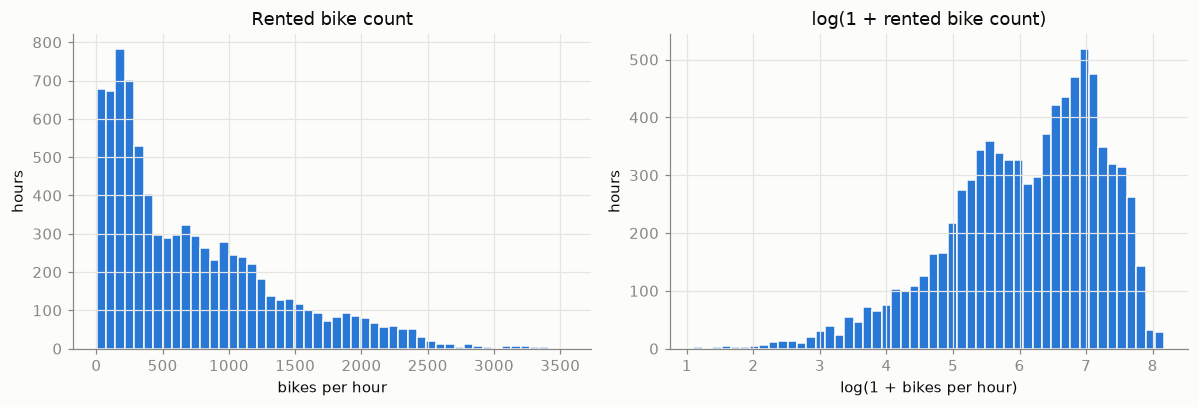

skewness raw: 1.14 | skewness log1p: -0.77


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df["count"], bins=50, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
axes[0].set(title="Rented bike count", xlabel="bikes per hour", ylabel="hours")
axes[1].hist(np.log1p(df["count"]), bins=50, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
axes[1].set(title="log(1 + rented bike count)", xlabel="log(1 + bikes per hour)", ylabel="hours")
fig.tight_layout()
plt.show()
print("skewness raw:", round(df["count"].skew(), 2),
      "| skewness log1p:", round(np.log1p(df["count"]).skew(), 2))

## Mean rentals by hour: weekday vs. weekend

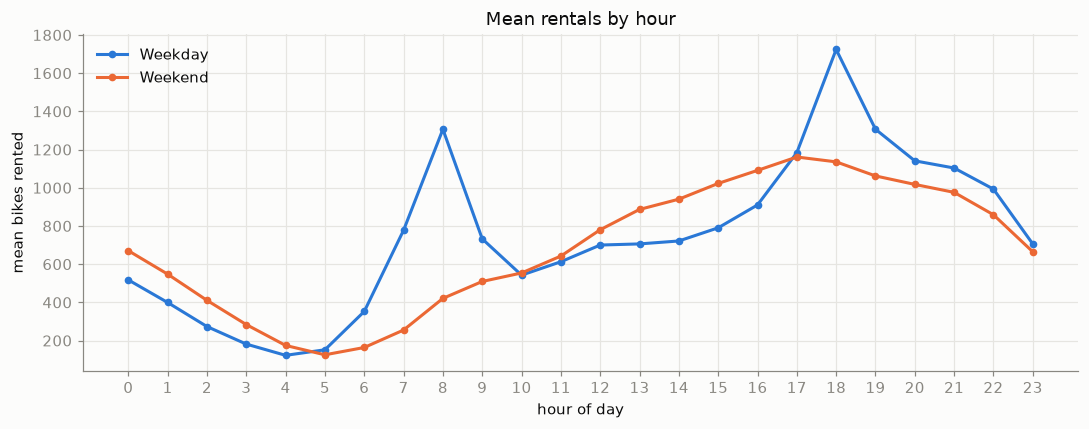

In [4]:
by_hour = df.groupby(["weekend", "hour"])["count"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(10, 4))
for col, color, label in [(0, BLUE, "Weekday"), (1, ORANGE, "Weekend")]:
    ax.plot(by_hour.index, by_hour[col], color=color, linewidth=2,
            marker="o", markersize=4, label=label)
ax.set(title="Mean rentals by hour", xlabel="hour of day",
       ylabel="mean bikes rented", xticks=range(0, 24))
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

## Mean rentals by season and holiday

In [5]:
print(df.groupby("season")["count"].agg(["mean", "median", "size"]).round(1).to_string())
print()
print(df.groupby("holiday")["count"].agg(["mean", "median", "size"]).round(1).to_string())

          mean  median  size
season                      
Autumn   924.1   856.0  1937
Spring   746.3   599.0  2160
Summer  1034.1   905.5  2208
Winter   225.5   203.0  2160

             mean  median  size
holiday                        
Holiday     529.2   259.0   408
No Holiday  739.3   561.0  8057


## Correlation heatmap (all original numeric columns + target)

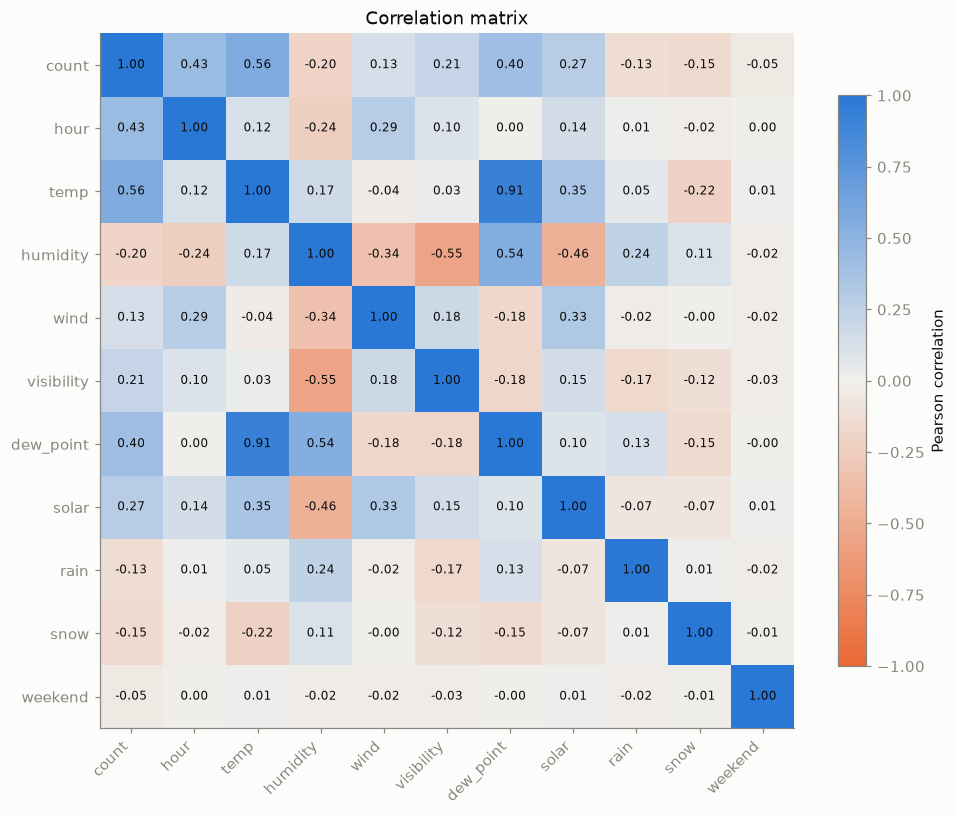

In [6]:
corr_cols = ["count", "hour", "temp", "humidity", "wind", "visibility",
             "dew_point", "solar", "rain", "snow", "weekend"]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
ax.grid(False)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color=INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Correlation matrix")
fig.tight_layout()
plt.show()

In [7]:
print("Correlation with target (count), sorted by absolute value:")
print(corr["count"].drop("count").sort_values(key=abs, ascending=False).round(3).to_string())
print()
print("Correlations among temp / humidity / dew_point / wind:")
print(corr.loc[["temp", "humidity", "dew_point", "wind"],
               ["temp", "humidity", "dew_point", "wind"]].round(3).to_string())

Correlation with target (count), sorted by absolute value:
temp          0.563
hour          0.425
dew_point     0.400
solar         0.274
visibility    0.212
humidity     -0.202
snow         -0.152
rain         -0.129
wind          0.125
weekend      -0.046

Correlations among temp / humidity / dew_point / wind:
            temp  humidity  dew_point   wind
temp       1.000     0.166      0.914 -0.038
humidity   0.166     1.000      0.539 -0.337
dew_point  0.914     0.539      1.000 -0.177
wind      -0.038    -0.337     -0.177  1.000
